# Model 1 (Change the name later)

## Imports

In [67]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from sklearn.dummy import DummyRegressor

import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone

from xgboost import XGBRegressor

from sklearn.model_selection import KFold, cross_validate, RandomizedSearchCV

from scipy.stats import randint, uniform


## Inputs

In [68]:
df = pd.read_csv('../src/output/airbnb_cmhc_merged.csv')

## Target variable

In [69]:
target = 'estimated_occupancy_l365d'

## Determine features

In [70]:
# Airbnb features
airbnb_numeric = [
    'price',
    'accommodates',
    'bathrooms',
    'bedrooms',
    'beds',
]

categorical = [
    'neighbourhood',
    'room_type',
    'property_category'
]

# CMHC features
cmhc_numeric = [
    'vacancy_rate',
    'med_rent',
    'total_units_2025',
    'pct_studio_units_2023',
    'pct_1b_units_2023',
    'pct_2b_units_2023',
]

features_a = airbnb_numeric + categorical
features_b = features_a + cmhc_numeric

## Data prep

In [71]:
numeric_columns = (list(set(airbnb_numeric + cmhc_numeric))+ [target])

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col], errors='coerce'
    )

df = df.replace([np.inf, -np.inf], np.nan)

# Keep observations with valid target and nightly price
df = df.dropna(subset=[target, 'price']).copy()

df = df[(df['price'] > 0) & (df[target].between(0, 365))].copy()

## Split into training and testing data

In [72]:
train, test = train_test_split(df, test_size=0.20, random_state=42)

y_train = train[target]
y_test = test[target]

## Build preprocessing and regression pipeline

In [73]:
def build_model(features):

    numerical = [
        c for c in features if c not in categorical
    ]

    preprocessing = ColumnTransformer([
        (
            'num',
            Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]),
            numerical
        ),
        (
            'cat',
            Pipeline([
                ('imputer', SimpleImputer(
                    strategy='most_frequent'
                )),
                ('encoder', OneHotEncoder(
                    handle_unknown='ignore'
                ))
            ]),
            categorical
        )
    ])

    return Pipeline([
        ('preprocessing', preprocessing),
        ('regression', Ridge(alpha=10.0))
    ])

## Train the models

In [74]:
# baseline
baseline = DummyRegressor(strategy='median')
baseline.fit(
    np.zeros((len(train), 1)),
    y_train
)

# model 1
model1 = build_model(features_a)
model1.fit(train[features_a], y_train)

# model 2
model2 = build_model(features_b)
model2.fit(train[features_b], y_train)

,steps,"[('preprocessing', ...), ('regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Predict annual occupied nights

In [75]:
predictions = {
    'Baseline': baseline.predict(
        np.zeros((len(test), 1))
    ),
    'Airbnb Only': model1.predict(
        test[features_a]
    ),
    'Airbnb + CMHC': model2.predict(
        test[features_b]
    )
}

## Calculate annual revenue

In [76]:
results = []

actual_nights = y_test.to_numpy()
nightly_prices = test['price'].to_numpy()

for name, pred_nights in predictions.items():

    pred_nights = np.clip(pred_nights, 0, 365)

    predicted_revenue = pred_nights * nightly_prices
    reference_revenue = actual_nights * nightly_prices

    results.append({
        'Model': name,
        'Occupancy_MAE': mean_absolute_error(
            actual_nights, pred_nights
        ),
        'Occupancy_R2': r2_score(
            actual_nights, pred_nights
        ),
        'Revenue_MAE': mean_absolute_error(
            reference_revenue, predicted_revenue
        ),
        'Revenue_R2': r2_score(
            reference_revenue, predicted_revenue
        )
    })

results_df = pd.DataFrame(results)

print('\nModel comparison:')
print(results_df.round(3).to_string(index=False))


Model comparison:
        Model  Occupancy_MAE  Occupancy_R2  Revenue_MAE  Revenue_R2
     Baseline         81.051        -0.153    28578.730       0.001
  Airbnb Only         79.652         0.075    28573.442      -0.054
Airbnb + CMHC         79.658         0.075    28578.736      -0.055


## Save prediction

In [77]:
output = test[['listing_id', 'neighbourhood', 'price']].copy()
output['actual_estimated_nights'] = actual_nights
output['predicted_nights'] = np.clip(predictions['Airbnb + CMHC'], 0, 365)
output['predicted_annual_revenue'] = (output['predicted_nights'] * output['price'])

output.to_csv('output/occupancy_revenue_predictions.csv', index=False)
results_df.to_csv('output/model_comparison.csv', index=False)


## Examine occupancy distributions

count    5845.000000
mean       90.300086
std        93.471053
min         0.000000
25%         0.000000
50%        54.000000
75%       180.000000
max       255.000000
Name: estimated_occupancy_l365d, dtype: float64

Occupancy percentiles:
0.01      0.0
0.05      0.0
0.25      0.0
0.50     54.0
0.75    180.0
0.95    255.0
0.99    255.0
Name: estimated_occupancy_l365d, dtype: float64


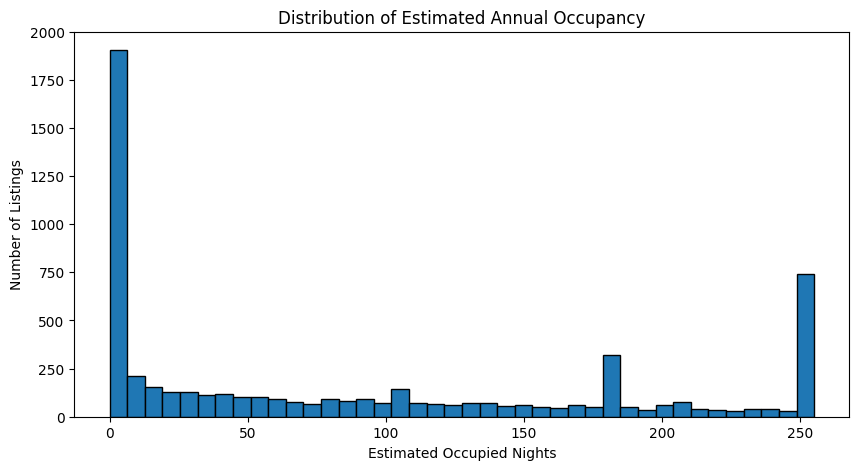

0.500      318.00
0.900      741.00
0.950      999.00
0.990     2041.96
0.995     2561.36
1.000    91294.33
Name: price, dtype: float64
               listing_id      neighbourhood     price  \
1450             48082323           Fairview  91294.33   
5410  1628421772010326873          Kitsilano  11411.80   
5317  1614803715947964548  Downtown Eastside  10099.00   
1711             54267743           Downtown   7368.00   
1845   621257811343758751           Downtown   5784.80   
1478             49199387           Fairview   5763.00   
5549  1642894319027210536           Downtown   5223.50   
3012  1038413325241000258    West Point Grey   4620.33   
897              30692099           Downtown   3819.00   
591              21487129          Kitsilano   3707.50   

      estimated_occupancy_l365d  
1450                         60  
5410                          0  
5317                         42  
1711                        246  
1845                         24  
1478                 

In [78]:
print(df[target].describe())

print("\nOccupancy percentiles:")
print(
    df[target].quantile([
        0.01, 0.05, 0.25, 0.50,
        0.75, 0.95, 0.99
    ])
)

plt.figure(figsize=(10, 5))
plt.hist(
    df[target].dropna(),
    bins=40,
    edgecolor="black"
)
plt.xlabel("Estimated Occupied Nights")
plt.ylabel("Number of Listings")
plt.title("Distribution of Estimated Annual Occupancy")
plt.show()

print(
    df["price"].quantile([
        0.50, 0.90, 0.95, 0.99, 0.995, 1.00
    ])
)

print(
    df.nlargest(
        10,
        "price"
    )[
        [
            "listing_id",
            "neighbourhood",
            "price",
            "estimated_occupancy_l365d"
        ]
    ]
)


# Non-Linear Model

In [79]:
rf_model = clone(model2)

In [80]:
rf_model.set_params(
    regression=RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
)

,steps,"[('preprocessing', ...), ('regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Train the Non-Linear Model 

In [81]:
rf_model.fit(train[features_b], y_train)

# Predict occupancy
rf_pred = np.clip(rf_model.predict(test[features_b]), 0, 365)

# Calculate revenue
rf_revenue_pred = rf_pred * test["price"].to_numpy()

actual_revenue = y_test.to_numpy() * test["price"].to_numpy()

print("Occupancy MAE:", mean_absolute_error(y_test, rf_pred))
print("Occupancy R2:", r2_score(y_test, rf_pred))
print("Revenue MAE:", mean_absolute_error(actual_revenue, rf_revenue_pred))
print("Revenue R2:", r2_score(actual_revenue, rf_revenue_pred))


Occupancy MAE: 74.86800270896532
Occupancy R2: 0.11912505671693752
Revenue MAE: 26941.963218548855
Revenue R2: 0.24174796903746654


## Random Forest without CMHC

In [82]:
rf_airbnb = clone(rf_model)

In [83]:
# Replace its preprocessing with Airbnb-only preprocessing
rf_airbnb.set_params(preprocessing=clone(model1.named_steps["preprocessing"]))

# Train on Airbnb features only
rf_airbnb.fit(train[features_a], y_train)

# Predict occupancy
pred_nights = np.clip(rf_airbnb.predict(test[features_a]), 0,365)

# Calculate revenue
pred_revenue = pred_nights * test["price"].to_numpy()
actual_revenue = y_test.to_numpy() * test["price"].to_numpy()
print("Occupancy MAE:", mean_absolute_error(y_test, pred_nights))
print("Occupancy R2:", r2_score(y_test, pred_nights))
print("Revenue MAE:", mean_absolute_error(actual_revenue, pred_revenue))
print("Revenue R2:", r2_score(actual_revenue, pred_revenue))


Occupancy MAE: 74.87039019270551
Occupancy R2: 0.1266805914916007
Revenue MAE: 26777.886757186403
Revenue R2: 0.26777254257033956


# XGBoost

## Parameters

In [84]:
xgb_params = {
    "n_estimators": 500,
    "max_depth": 4,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 5,
    "reg_lambda": 10.0,
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1
}

In [85]:
xgb_airbnb = Pipeline([
    (
        "preprocessing",
        clone(model1.named_steps["preprocessing"])
    ),
    (
        "regression",
        XGBRegressor(**xgb_params)
    )
])

xgb_cmhc = Pipeline([
    (
        "preprocessing",
        clone(model2.named_steps["preprocessing"])
    ),
    (
        "regression",
        XGBRegressor(**xgb_params)
    )
])


## Train models

In [86]:
xgb_airbnb.fit(train[features_a], y_train)
xgb_cmhc.fit(train[features_b], y_train)

,steps,"[('preprocessing', ...), ('regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Cross-Validation

In [87]:
models = {
    "Random Forest": rf_airbnb,
    "XGBoost": xgb_airbnb
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    scores = cross_validate(
        clone(model),
        train[features_a],
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "R2": "r2"
        },
        n_jobs=1
    )

    results.append({
        "Model": name,
        "Mean Occupancy MAE": -scores[
            "test_MAE"
        ].mean(),
        "Std Occupancy MAE": scores[
            "test_MAE"
        ].std(),
        "Mean Occupancy R2": scores[
            "test_R2"
        ].mean(),
        "Std Occupancy R2": scores[
            "test_R2"
        ].std()
    })

cv_results = pd.DataFrame(results)

print(cv_results.round(3))

           Model  Mean Occupancy MAE  Std Occupancy MAE  Mean Occupancy R2  \
0  Random Forest              75.958              0.989              0.074   
1        XGBoost              75.658              0.726              0.093   

   Std Occupancy R2  
0             0.020  
1             0.026  


## 	XGBoost Hyperparameter Tuning

In [88]:
param_distributions = {
    "regression__n_estimators": randint(200, 1000),
    "regression__max_depth": randint(2, 8),
    "regression__learning_rate": uniform(0.01, 0.09),
    "regression__subsample": uniform(0.6, 0.4),
    "regression__colsample_bytree": uniform(0.6, 0.4),
    "regression__min_child_weight": randint(1, 12),
    "regression__reg_lambda": uniform(1, 20)
}

search = RandomizedSearchCV(
    estimator=clone(xgb_airbnb),
    param_distributions=param_distributions,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

search.fit(
    train[features_a],
    y_train
)

print("Best parameters:")
print(search.best_params_)

print("\nBest cross-validation MAE:")
print(-search.best_score_)

best_xgb = search.best_estimator_

tuning_results = pd.DataFrame(search.cv_results_)

tuning_results.to_csv(
    "output/xgboost_tuning_results.csv",
    index=False
)


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters:
{'regression__colsample_bytree': np.float64(0.9637281608315128), 'regression__learning_rate': np.float64(0.03329019834400152), 'regression__max_depth': 5, 'regression__min_child_weight': 2, 'regression__n_estimators': 589, 'regression__reg_lambda': np.float64(5.158833257363776), 'regression__subsample': np.float64(0.8270801311279966)}

Best cross-validation MAE:
75.07514038085938


In [89]:
# Predict occupied nights
tuned_pred = np.clip(best_xgb.predict(test[features_a]), 0, 365)

# Calculate annual revenue
nightly_prices = test["price"].to_numpy()

tuned_revenue = tuned_pred * nightly_prices

actual_revenue = (y_test.to_numpy() * nightly_prices)

# Evaluation
print("\nTUNED XGBOOST RESULTS")
print("Occupancy MAE:",mean_absolute_error(y_test, tuned_pred))
print("Occupancy RMSE:", np.sqrt(mean_squared_error(y_test, tuned_pred)))
print("Occupancy R2:",r2_score(y_test, tuned_pred))
print("Revenue MAE:",mean_absolute_error(actual_revenue, tuned_revenue))
print("Revenue RMSE:",np.sqrt(mean_squared_error(actual_revenue, tuned_revenue)))
print("Revenue R2:", r2_score(actual_revenue, tuned_revenue))



TUNED XGBOOST RESULTS
Occupancy MAE: 74.12113952636719
Occupancy RMSE: 88.40948374697281
Occupancy R2: 0.12499046325683594
Revenue MAE: 26605.973893953844
Revenue RMSE: 40651.72701035809
Revenue R2: 0.27477915628099614


## Evaluate the models

In [90]:
def evaluate_model(name, model, features):

    pred_nights = np.clip(
        model.predict(test[features]),
        0,
        365
    )

    actual_nights = y_test.to_numpy()
    prices = test["price"].to_numpy()

    pred_revenue = pred_nights * prices
    actual_revenue = actual_nights * prices

    return {
        "Model": name,
        "Occupancy_MAE": mean_absolute_error(actual_nights, pred_nights),
        "Occupancy_RMSE": np.sqrt(mean_squared_error(actual_nights, pred_nights)),
        "Occupancy_R2": r2_score(actual_nights, pred_nights),
        "Revenue_MAE": mean_absolute_error(actual_revenue, pred_revenue),
        "Revenue_RMSE": np.sqrt(mean_squared_error(actual_revenue, pred_revenue)),
        "Revenue_R2": r2_score(actual_revenue, pred_revenue)
    }


In [91]:
error_analysis = test[
    [
        "listing_id",
        "neighbourhood",
        "property_category",
        "room_type",
        "price"
    ]
].copy()

error_analysis["actual_occupancy"] = y_test.to_numpy()
error_analysis["predicted_occupancy"] = tuned_pred

error_analysis["occupancy_abs_error"] = np.abs(
    error_analysis["actual_occupancy"] -
    error_analysis["predicted_occupancy"]
)

error_analysis["actual_revenue"] = (
    error_analysis["actual_occupancy"] *
    error_analysis["price"]
)

error_analysis["predicted_revenue"] = (
    error_analysis["predicted_occupancy"] *
    error_analysis["price"]
)

error_analysis["revenue_abs_error"] = np.abs(
    error_analysis["actual_revenue"] -
    error_analysis["predicted_revenue"]
)

# Compare prediction errors by neighbourhood
neighbourhood_errors = (
    error_analysis
    .groupby("neighbourhood")
    .agg(
        listings=("listing_id", "count"),
        occupancy_mae=("occupancy_abs_error", "mean"),
        revenue_mae=("revenue_abs_error", "mean")
    )
    .sort_values("revenue_mae", ascending=False)
)

print("\nERROR BY NEIGHBOURHOOD")
print(neighbourhood_errors.round(2))

# Compare errors by property category
property_errors = (
    error_analysis
    .groupby("property_category")
    .agg(
        listings=("listing_id", "count"),
        occupancy_mae=("occupancy_abs_error", "mean"),
        revenue_mae=("revenue_abs_error", "mean")
    )
    .sort_values("revenue_mae", ascending=False)
)

print("\nERROR BY PROPERTY CATEGORY")
print(property_errors.round(2))

# Export
error_analysis.to_csv(
    "output/tuned_xgboost_error_analysis.csv",
    index=False
)


ERROR BY NEIGHBOURHOOD
                          listings  occupancy_mae  revenue_mae
neighbourhood                                                 
Shaughnessy                     13          56.84     38378.09
Downtown                       285          80.51     32802.47
Victoria-Fraserview             38          94.35     31730.62
Kitsilano                       85          71.40     31466.58
Arbutus Ridge                   18          80.35     31256.02
Downtown Eastside               67          73.04     30638.43
Oakridge                        26          55.96     29616.92
Riley Park                      52          73.88     29378.36
Kensington-Cedar Cottage        64          72.61     27087.29
Strathcona                       6         107.62     26463.71
Killarney                       21          73.02     26186.23
South Cambie                     9          75.31     26185.80
West Point Grey                 27          58.81     23345.25
Hastings-Sunrise               

## Example Nightly Prices

In [92]:
error_analysis["price_group"] = pd.qcut(
    error_analysis["price"],
    q=4,
    duplicates="drop"
)

price_errors = (
    error_analysis.groupby(
        "price_group",
        observed=True
    )
    .agg(
        listings=("listing_id", "count"),
        median_price=("price", "median"),
        occupancy_mae=("occupancy_abs_error", "mean"),
        revenue_mae=("revenue_abs_error", "mean"),
        median_revenue=("actual_revenue", "median")
    )
)

print("\nERROR BY NIGHTLY PRICE")
print(price_errors.round(2))

# Check extreme revenue errors
print("\nTOP 10 LARGEST REVENUE ERRORS")

print(
    error_analysis.nlargest(
        10,
        "revenue_abs_error"
    )[
        [
            "listing_id",
            "neighbourhood",
            "property_category",
            "price",
            "actual_occupancy",
            "predicted_occupancy",
            "actual_revenue",
            "predicted_revenue",
            "revenue_abs_error"
        ]
    ]
)



ERROR BY NIGHTLY PRICE
                   listings  median_price  occupancy_mae  revenue_mae  \
price_group                                                             
(6.169, 138.0]          293         42.60          77.33      3906.00   
(138.0, 320.5]          292        239.65          76.05     18202.40   
(320.5, 494.51]         292        394.10          76.28     30366.34   
(494.51, 11411.8]       292        650.00          66.80     54026.90   

                   median_revenue  
price_group                        
(6.169, 138.0]                0.0  
(138.0, 320.5]            19923.0  
(320.5, 494.51]           35565.0  
(494.51, 11411.8]         30433.5  

TOP 10 LARGEST REVENUE ERRORS
               listing_id      neighbourhood           property_category  \
2654   928202990992852367         Riley Park  Entire Houses / Townhouses   
1205             39973193           Oakridge  Entire Houses / Townhouses   
591              21487129          Kitsilano  Entire Houses / 

In [94]:
zero_occupancy = (
    error_analysis.assign(
        zero_occupancy=error_analysis["actual_occupancy"].eq(0)
    )
    .groupby("price_group", observed=True)
    .agg(
        listings=("listing_id", "count"),
        zero_occupancy_count=("zero_occupancy", "sum"),
        zero_occupancy_pct=("zero_occupancy", "mean")
    )
)

zero_occupancy["zero_occupancy_pct"] *= 100

print("\nZERO OCCUPANCY BY PRICE GROUP")
print(zero_occupancy.round(2))

# 2. Nightly price distribution
print("\nPRICE DISTRIBUTION")
print(
    error_analysis["price"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)

# 3. Inspect the 10 most expensive listings
print("\nMOST EXPENSIVE LISTINGS")
print(
    error_analysis.nlargest(10, "price")[
        [
            "listing_id",
            "neighbourhood",
            "property_category",
            "price",
            "actual_occupancy",
            "predicted_occupancy",
            "actual_revenue",
            "predicted_revenue"
        ]
    ].to_string(index=False)
)

# 4. Percentage of error contributed by expensive listings
total_abs_error = error_analysis["revenue_abs_error"].sum()

error_contribution = (
    error_analysis.groupby("price_group", observed=True)
    ["revenue_abs_error"]
    .sum()
    .div(total_abs_error)
    .mul(100)
)

print("\nSHARE OF TOTAL ABSOLUTE REVENUE ERROR (%)")
print(error_contribution.round(2))


ZERO OCCUPANCY BY PRICE GROUP
                   listings  zero_occupancy_count  zero_occupancy_pct
price_group                                                          
(6.169, 138.0]          293                   186               63.48
(138.0, 320.5]          292                    47               16.10
(320.5, 494.51]         292                    43               14.73
(494.51, 11411.8]       292                    70               23.97

PRICE DISTRIBUTION
count     1169.000000
mean       387.383370
std        490.564683
min          6.170000
50%        320.500000
90%        735.960000
95%       1004.600000
99%       2015.120000
max      11411.800000
Name: price, dtype: float64

MOST EXPENSIVE LISTINGS
         listing_id    neighbourhood          property_category    price  actual_occupancy  predicted_occupancy  actual_revenue  predicted_revenue
1628421772010326873        Kitsilano Entire Houses / Townhouses 11411.80                 0             9.098192            0.00    

In [95]:
zero_listings = df.loc[
    df["estimated_occupancy_l365d"].eq(0)
].copy()

print("ZERO OCCUPANCY LISTINGS:", len(zero_listings))

print("\nAVAILABILITY STATUS")
print(
    zero_listings["has_availability"]
    .value_counts(dropna=False)
)

print("\nAVAILABILITY 365 DISTRIBUTION")
print(
    zero_listings["availability_365"]
    .describe()
)

print("\nZERO OCCUPANCY BY ROOM TYPE")
print(
    zero_listings["room_type"]
    .value_counts(dropna=False)
)

print("\nZERO OCCUPANCY BY PROPERTY CATEGORY")
print(
    zero_listings["property_category"]
    .value_counts(dropna=False)
)

# Examine how often zero-occupancy listings
# are unavailable for the next 365 days.

print("\nZERO OCCUPANCY AND ZERO AVAILABILITY")

print(
    pd.crosstab(
        zero_listings["has_availability"],
        zero_listings["availability_365"].eq(0),
        dropna=False
    )
)


ZERO OCCUPANCY LISTINGS: 1629

AVAILABILITY STATUS
has_availability
True    1629
Name: count, dtype: int64

AVAILABILITY 365 DISTRIBUTION
count    1629.000000
mean      234.958870
std       117.888503
min         2.000000
25%       132.000000
50%       269.000000
75%       355.000000
max       365.000000
Name: availability_365, dtype: float64

ZERO OCCUPANCY BY ROOM TYPE
room_type
Entire home/apt    1192
Private room        432
Shared room           5
Name: count, dtype: int64

ZERO OCCUPANCY BY PROPERTY CATEGORY
property_category
Entire Apartment / Condos                713
Private Rooms                            430
Entire Houses / Townhouses               393
Secondary Suites / Guest Units            77
Niche / Unconventional Accommodations      8
Shared Rooms                               5
Commercial / Hospitality                   3
Name: count, dtype: int64

ZERO OCCUPANCY AND ZERO AVAILABILITY
availability_365  False
has_availability       
True               1629


In [96]:
# Use your full dataset, including original review columns
review_analysis = df[
    [
        "estimated_occupancy_l365d",
        "review_count",
        "review_count_365d",
        "availability_365"
    ]
].dropna(subset=["estimated_occupancy_l365d"]).copy()

review_analysis["zero_occupancy"] = (
    review_analysis["estimated_occupancy_l365d"] == 0
)

review_analysis["has_reviews_365d"] = (
    review_analysis["review_count_365d"] > 0
)

# Compare review activity
review_summary = (
    review_analysis.groupby("zero_occupancy")
    .agg(
        listings=("zero_occupancy", "size"),
        median_total_reviews=("review_count", "median"),
        median_reviews_365d=("review_count_365d", "median"),
        pct_with_reviews_365d=("has_reviews_365d", "mean"),
        median_availability=("availability_365", "median")
    )
)

review_summary["pct_with_reviews_365d"] *= 100

print("\nREVIEW ACTIVITY VS ZERO OCCUPANCY")
print(review_summary.round(2).to_string())

# Cross-tabulate zero occupancy against recent reviews
print("\nZERO OCCUPANCY VS RECENT REVIEWS")
print(
    pd.crosstab(
        review_analysis["zero_occupancy"],
        review_analysis["has_reviews_365d"],
        margins=True
    )
)

# Specifically investigate zero-occupancy listings
# that have received reviews within the past year
suspicious = review_analysis[
    (review_analysis["zero_occupancy"])
    & (review_analysis["has_reviews_365d"])
]

print("\nZERO OCCUPANCY LISTINGS WITH RECENT REVIEWS:")
print(len(suspicious))


REVIEW ACTIVITY VS ZERO OCCUPANCY
                listings  median_total_reviews  median_reviews_365d  pct_with_reviews_365d  median_availability
zero_occupancy                                                                                                 
False               4216                  31.0                 14.0                  99.79                154.0
True                1629                   5.0                  0.0                   1.35                269.0

ZERO OCCUPANCY VS RECENT REVIEWS
has_reviews_365d  False  True   All
zero_occupancy                     
False                 9  4207  4216
True               1607    22  1629
All                1616  4229  5845

ZERO OCCUPANCY LISTINGS WITH RECENT REVIEWS:
22


In [98]:
review_occ = df[
    [
        "estimated_occupancy_l365d",
        "review_count_365d"
    ]
].dropna().copy()

# Keep listings with positive recent reviews
review_occ = review_occ[
    review_occ["review_count_365d"] > 0
].copy()

# Estimated occupied nights per review
review_occ["nights_per_review"] = (
    review_occ["estimated_occupancy_l365d"]
    / review_occ["review_count_365d"]
)

print("\nNIGHTS PER REVIEW DISTRIBUTION")

print(
    review_occ["nights_per_review"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
)

print("\nCORRELATION BETWEEN REVIEWS AND OCCUPANCY")

print(
    review_occ[
        [
            "review_count_365d",
            "estimated_occupancy_l365d"
        ]
    ].corr()
)

# Look at average occupancy by review count
review_occ["review_group"] = pd.cut(
    review_occ["review_count_365d"],
    bins=[0, 1, 5, 10, 20, 50, np.inf],
    labels=[
        "1 review",
        "2-5 reviews",
        "6-10 reviews",
        "11-20 reviews",
        "21-50 reviews",
        "51+ reviews"
    ]
)

review_group_summary = (
    review_occ.groupby(
        "review_group",
        observed=True
    )
    .agg(
        listings=("estimated_occupancy_l365d", "size"),
        median_occupancy=("estimated_occupancy_l365d", "median"),
        median_nights_per_review=("nights_per_review", "median")
    )
)

print("\nOCCUPANCY BY REVIEW COUNT")
print(review_group_summary.round(2).to_string())


NIGHTS PER REVIEW DISTRIBUTION
count    4229.000000
mean       20.154379
std        45.246204
min         0.000000
10%         5.100000
25%         6.000000
50%         6.000000
75%         6.000000
90%        31.875000
max       255.000000
Name: nights_per_review, dtype: float64

CORRELATION BETWEEN REVIEWS AND OCCUPANCY
                           review_count_365d  estimated_occupancy_l365d
review_count_365d                   1.000000                   0.700883
estimated_occupancy_l365d           0.700883                   1.000000

OCCUPANCY BY REVIEW COUNT
               listings  median_occupancy  median_nights_per_review
review_group                                                       
1 review            564               6.0                      6.00
2-5 reviews         781              24.0                      6.00
6-10 reviews        536              48.0                      6.00
11-20 reviews       762              90.0                      6.00
21-50 reviews      1212 

In [99]:

# ======================================================
# Check whether estimated occupancy follows reviews * 6
# ======================================================

import numpy as np
import pandas as pd

check_df = df[
    [
        "review_count_365d",
        "estimated_occupancy_l365d"
    ]
].dropna().copy()

check_df["six_night_estimate"] = (
    check_df["review_count_365d"] * 6
)

check_df["matches_exactly"] = np.isclose(
    check_df["estimated_occupancy_l365d"],
    check_df["six_night_estimate"],
    atol=0.01
)

check_df["within_one_night"] = (
    (
        check_df["estimated_occupancy_l365d"]
        - check_df["six_night_estimate"]
    ).abs() <= 1
)

print("\nEXACT MATCH PERCENTAGE")
print(check_df["matches_exactly"].mean() * 100)

print("\nWITHIN ONE NIGHT PERCENTAGE")
print(check_df["within_one_night"].mean() * 100)

# Check for possible annual occupancy cap
print("\nMAXIMUM ESTIMATED OCCUPANCY")
print(check_df["estimated_occupancy_l365d"].max())

# Compare against a capped formula
check_df["capped_estimate"] = np.minimum(
    check_df["review_count_365d"] * 6,
    255
)

check_df["matches_capped"] = np.isclose(
    check_df["estimated_occupancy_l365d"],
    check_df["capped_estimate"],
    atol=0.01
)

print("\nMATCHES 6 * REVIEWS CAPPED AT 255 (%)")
print(check_df["matches_capped"].mean() * 100)



EXACT MATCH PERCENTAGE
74.44260941370769

WITHIN ONE NIGHT PERCENTAGE
74.44260941370769

MAXIMUM ESTIMATED OCCUPANCY
255

MATCHES 6 * REVIEWS CAPPED AT 255 (%)
85.81750619322874


In [100]:

# ======================================================
# Analyze listings that do not match the occupancy formula
# ======================================================

check_df["difference"] = (
    check_df["estimated_occupancy_l365d"]
    - check_df["capped_estimate"]
)

unmatched = check_df.loc[
    ~check_df["matches_capped"]
].copy()

print("UNMATCHED LISTINGS:", len(unmatched))

print("\nDIFFERENCE DISTRIBUTION")
print(
    unmatched["difference"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
)

print("\nMOST COMMON DIFFERENCES")
print(
    unmatched["difference"]
    .round(2)
    .value_counts()
    .head(15)
)

print("\nSAMPLE OF UNMATCHED LISTINGS")
print(
    unmatched[
        [
            "review_count_365d",
            "estimated_occupancy_l365d",
            "capped_estimate",
            "difference"
        ]
    ].head(20).to_string(index=False)
)


UNMATCHED LISTINGS: 687

DIFFERENCE DISTRIBUTION
count    687.000000
mean     126.059680
std       92.436824
min      -30.000000
10%        6.000000
25%       12.000000
50%      174.000000
75%      174.000000
90%      243.000000
max      249.000000
Name: difference, dtype: float64

MOST COMMON DIFFERENCES
difference
 174.0    230
 6.0       97
 243.0     87
-6.0       34
 237.0     27
 12.0      17
 168.0     12
 176.0     11
 24.0      10
 162.0      8
 18.0       8
-12.0       7
-18.0       7
 249.0      7
 108.0      7
Name: count, dtype: int64

SAMPLE OF UNMATCHED LISTINGS
 review_count_365d  estimated_occupancy_l365d  capped_estimate  difference
              35.0                        216            210.0         6.0
               1.0                        180              6.0       174.0
              19.0                        190            114.0        76.0
               1.0                         60              6.0        54.0
               1.0                       

## Result comparison

In [93]:
results = [
    evaluate_model(
        "XGBoost Airbnb Only",
        xgb_airbnb,
        features_a
    ),
    evaluate_model(
        "XGBoost Airbnb + CMHC",
        xgb_cmhc,
        features_b
    )
]

xgb_results = pd.DataFrame(results)

print(xgb_results.round(3).to_string(index=False))


                Model  Occupancy_MAE  Occupancy_RMSE  Occupancy_R2  Revenue_MAE  Revenue_RMSE  Revenue_R2
  XGBoost Airbnb Only         75.192          88.029         0.133    26767.235     40934.596       0.265
XGBoost Airbnb + CMHC         75.189          88.286         0.127    26831.800     41327.752       0.250


In [101]:

# ======================================================
# FINAL MODEL COMPARISON AND EXPORT
# ======================================================

from pathlib import Path

Path("output").mkdir(exist_ok=True)

# Compare the main candidate models
final_results = [
    evaluate_model(
        "Random Forest Airbnb Only",
        rf_airbnb,
        features_a
    ),
    evaluate_model(
        "XGBoost Airbnb Only",
        xgb_airbnb,
        features_a
    ),
    evaluate_model(
        "XGBoost Airbnb + CMHC",
        xgb_cmhc,
        features_b
    ),
    evaluate_model(
        "Tuned XGBoost Airbnb Only",
        best_xgb,
        features_a
    )
]

final_comparison = pd.DataFrame(final_results)

print("\nFINAL MODEL COMPARISON")
print(
    final_comparison.round(3).to_string(index=False)
)

final_comparison.to_csv(
    "output/final_model_comparison.csv",
    index=False
)

# Export tuned XGBoost test predictions
final_predictions = test[
    [
        "listing_id",
        "neighbourhood",
        "property_category",
        "room_type",
        "price"
    ]
].copy()

final_predictions["estimated_occupied_nights"] = (
    y_test.to_numpy()
)

final_predictions["predicted_occupied_nights"] = (
    np.clip(
        best_xgb.predict(test[features_a]),
        0,
        365
    )
)

final_predictions["estimated_annual_revenue"] = (
    final_predictions["estimated_occupied_nights"]
    * final_predictions["price"]
)

final_predictions["predicted_annual_revenue"] = (
    final_predictions["predicted_occupied_nights"]
    * final_predictions["price"]
)

final_predictions.to_csv(
    "output/final_airbnb_predictions.csv",
    index=False
)

print("\nExport completed:")
print("output/final_model_comparison.csv")
print("output/final_airbnb_predictions.csv")



FINAL MODEL COMPARISON
                    Model  Occupancy_MAE  Occupancy_RMSE  Occupancy_R2  Revenue_MAE  Revenue_RMSE  Revenue_R2
Random Forest Airbnb Only         74.870          88.324         0.127    26777.887     40847.630       0.268
      XGBoost Airbnb Only         75.192          88.029         0.133    26767.235     40934.596       0.265
    XGBoost Airbnb + CMHC         75.189          88.286         0.127    26831.800     41327.752       0.250
Tuned XGBoost Airbnb Only         74.121          88.409         0.125    26605.974     40651.727       0.275

Export completed:
output/final_model_comparison.csv
output/final_airbnb_predictions.csv
